# ДЗ 2. Exclusive Self Attention

S. Zhai, *Exclusive Self Attention*, [arXiv:2603.09078](https://arxiv.org/abs/2603.09078).

XSA вычитает из выхода внимания его проекцию на value того же токена:

$$z_i = y_i - \frac{y_i^\top v_i}{\lVert v_i \rVert_2^2}\, v_i$$

GPT на 30M параметров, FineWeb, 100M токенов на запуск, 3 сида. Результаты пишутся на Google Drive, при перезапуске готовые запуски пропускаются. На A100 80GB `PRESET = "quick"` идёт около 50 минут, `"full"` около 2 часов.

In [1]:
!nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv
!pip -q install tiktoken

name, memory.total [MiB], driver_version
NVIDIA A100-SXM4-80GB, 81920 MiB, 580.82.07


In [2]:
import gc
import glob
import json
import math
import os
import time
import urllib.request
import warnings
from dataclasses import asdict, dataclass

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tiktoken
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import Image, display
from scipy import stats

PRESET = "full"    # "quick" или "full"
USE_DRIVE = True   # результаты на Google Drive переживают обрыв сессии

LOCAL = "/content" if os.path.isdir("/content") else os.getcwd()
ROOT = LOCAL
if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        ROOT = "/content/drive/MyDrive/xsa_hw2"
    except Exception as e:
        print("Drive не подключён, пишу локально:", e)
RESULTS = os.path.join(ROOT, "results")
DATA = os.path.join(LOCAL, "data")

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
COMPILE = DEVICE == "cuda"
GPU = torch.cuda.get_device_name(0) if DEVICE == "cuda" else "cpu"
GPU_MEM_GB = torch.cuda.get_device_properties(0).total_memory / 2**30 if DEVICE == "cuda" else 0.0
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
warnings.filterwarnings("ignore", message="Mean of empty slice")


def amp():
    return torch.autocast(DEVICE, dtype=torch.bfloat16, enabled=DEVICE == "cuda")


def sync():
    if DEVICE == "cuda":
        torch.cuda.synchronize()


SIZES = {            # n_layer, n_embd, n_head; head_dim = 64
    "XS": (4, 256, 4),
    "S": (6, 384, 6),  # основная модель
    "M": (8, 512, 8),
}
TRAIN = dict(
    tokens=100_000_000,         # токенов на один запуск
    batch_tokens=2**17,         # 131k токенов на шаг оптимизатора
    micro_tokens=2**15 if GPU_MEM_GB >= 35 else 2**14,
    lr=2e-3,
    warmup_frac=0.05,
    min_lr_frac=0.1,            # косинус до 0.1 от максимума, как в статье
    weight_decay=0.1,
    betas=(0.9, 0.95),
    grad_clip=1.0,
    eval_every=100,
    eval_tokens=2**21,          # val во время обучения, 2M токенов
    final_eval_tokens=10 * 2**20,  # итоговый val, 10M токенов
    timing_skip=20,             # первые шаги (компиляция) не входят во время шага
)
SEEDS = (0, 1, 2)

print(f"{GPU}, {GPU_MEM_GB:.0f} GB | torch {torch.__version__} | результаты: {RESULTS}")

Mounted at /content/drive
NVIDIA A100-SXM4-80GB, 79 GB | torch 2.11.0+cu130 | результаты: /content/drive/MyDrive/xsa_hw2/results


## 1. XSA

`xsa` повторяет Algorithm 1 из статьи. Тест сверяет её с формулой (2), посчитанной циклом по позициям, и проверяет градиент. На первой позиции $y_1 = v_1$, поэтому у XSA выход внимания там нулевой. `xsa_fused` компилирует ту же функцию в одно ядро через `torch.compile`, она нужна для бенчмарка.

In [3]:
def xsa(y, v):
    """Algorithm 1 из статьи: убрать из y_i компоненту вдоль v_i. y, v: (B, H, T, head_dim)."""
    vn = F.normalize(v, dim=-1)
    return y - (y * vn).sum(dim=-1, keepdim=True) * vn


xsa_fused = torch.compile(xsa, dynamic=True) if COMPILE else xsa


def xsa_reference(x, Wq, Wk, Wv, H):
    """Формула (2) напрямую, циклом по позициям. x: (T, D)."""
    T, D = x.shape
    dh = D // H
    q, k, v = ((x @ W).view(T, H, dh) for W in (Wq, Wk, Wv))
    z = torch.zeros_like(q)
    for i in range(T):
        a = torch.softmax(torch.einsum("hd,jhd->hj", q[i], k[: i + 1]) / math.sqrt(dh), dim=-1)
        y = torch.einsum("hj,jhd->hd", a, v[: i + 1])
        z[i] = y - (y * v[i]).sum(-1, keepdim=True) * v[i] / (v[i] * v[i]).sum(-1, keepdim=True)
    return z


def test_xsa():
    g = torch.Generator().manual_seed(0)
    T, D, H = 16, 32, 4
    x = torch.randn(T, D, generator=g, dtype=torch.float64)
    Wq, Wk, Wv = (torch.randn(D, D, generator=g, dtype=torch.float64) / math.sqrt(D) for _ in range(3))
    q, k, v = ((x @ W).view(1, T, H, D // H).transpose(1, 2) for W in (Wq, Wk, Wv))
    z = xsa(F.scaled_dot_product_attention(q, k, v, is_causal=True), v)
    assert torch.allclose(z, xsa_reference(x, Wq, Wk, Wv, H).transpose(0, 1)[None], atol=1e-10)
    proj = (z * F.normalize(v, dim=-1)).sum(-1).abs().max().item()
    assert proj < 1e-10 and torch.allclose(xsa(z, v), z, atol=1e-10)
    assert z[..., 0, :].abs().max() < 1e-12  # первый токен видит только себя: y_1 = v_1, значит z_1 = 0
    y = torch.randn(1, H, T, D // H, dtype=torch.float64, requires_grad=True)
    assert torch.autograd.gradcheck(xsa, (y, v.detach().requires_grad_()))
    print(f"формула (2): ok | max |⟨z_i, v_i/‖v_i‖⟩| = {proj:.1e} | z_1 = 0 | gradcheck: ok")
    if COMPILE:
        yb, vb = (torch.randn(8, 6, 1024, 64, device=DEVICE, dtype=torch.bfloat16) for _ in range(2))
        diff = (xsa_fused(yb, vb).float() - xsa(yb, vb).float()).abs().max().item()
        print(f"fused и eager в bf16: max |разница| = {diff:.1e}")


test_xsa()

формула (2): ok | max |⟨z_i, v_i/‖v_i‖⟩| = 1.0e-15 | z_1 = 0 | gradcheck: ok
fused и eager в bf16: max |разница| = 3.1e-02


## 2. Модель

nanoGPT с изменениями из статьи: RoPE и LayerNorm после эмбеддингов. Pre-LN, GELU, без bias, эмбеддинги связаны с выходным слоем.

Варианты: `base`, `xsa` (XSA во всех слоях, как в статье) и `xsa_half` (только в верхней половине слоёв, так XSA ставили в OpenAI Parameter Golf). Sink-токены как у Xiao et al.: `n_sinks` обучаемых векторов в начале последовательности. В режиме `stats` внимание считается явно, чтобы снять величины с рис. 1.

In [4]:
@dataclass
class GPTConfig:
    n_layer: int = 6
    n_embd: int = 384
    n_head: int = 6
    seq_len: int = 1024
    vocab_size: int = 50304     # 50257 токенов GPT-2, округлено до кратного 128
    xsa_layers: tuple = ()      # номера слоёв с XSA
    n_sinks: int = 0
    rope_base: float = 10000.0


def xsa_layers(variant, n_layer):
    return {"base": (), "xsa": tuple(range(n_layer)), "xsa_half": tuple(range(n_layer // 2, n_layer))}[variant]


def rope_cache(T, dim, base, device=None):
    inv_freq = 1.0 / base ** (torch.arange(0, dim, 2, device=device).float() / dim)
    freqs = torch.outer(torch.arange(T, device=device).float(), inv_freq)
    return freqs.cos()[None, None], freqs.sin()[None, None]


def apply_rope(x, cos, sin):
    x1, x2 = x.float().chunk(2, dim=-1)
    return torch.cat([x1 * cos - x2 * sin, x1 * sin + x2 * cos], dim=-1).type_as(x)


STAT_KEYS = ("vv", "a_self", "a_first", "yv", "zv")


class Attention(nn.Module):
    def __init__(self, cfg, layer):
        super().__init__()
        self.n_head, self.head_dim = cfg.n_head, cfg.n_embd // cfg.n_head
        self.qkv = nn.Linear(cfg.n_embd, 3 * cfg.n_embd, bias=False)
        self.proj = nn.Linear(cfg.n_embd, cfg.n_embd, bias=False)
        self.use_xsa = layer in cfg.xsa_layers
        self.xsa_fn = xsa
        self.stats = None

    def forward(self, x, cos, sin):
        B, T, C = x.shape
        q, k, v = self.qkv(x).view(B, T, 3, self.n_head, self.head_dim).permute(2, 0, 3, 1, 4)
        q, k = apply_rope(q, cos, sin), apply_rope(k, cos, sin)
        if self.stats is None:
            y = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        else:
            y = self.attention_with_stats(q, k, v)
        if self.use_xsa:
            y = self.xsa_fn(y, v)
            if self.stats is not None:
                self.stats["zv"].append(F.cosine_similarity(y.float(), v.float(), dim=-1)[..., 1:].mean().item())
        return self.proj(y.transpose(1, 2).reshape(B, T, C))

    def attention_with_stats(self, q, k, v):
        T = q.shape[2]
        q, k, v = q.float(), k.float(), v.float()
        mask = torch.ones(T, T, dtype=torch.bool, device=q.device).tril()
        att = (q @ k.transpose(-2, -1) / math.sqrt(self.head_dim)).masked_fill(~mask, float("-inf")).softmax(-1)
        y = att @ v
        s = F.normalize(v, dim=-1).sum(2)
        self.stats["vv"].append((((s * s).sum(-1) - T) / (T * (T - 1))).mean().item())  # cos(v_i, v_j), i ≠ j
        self.stats["a_self"].append(att.diagonal(dim1=-2, dim2=-1)[..., 1:].mean().item())  # a_ii, i > 1
        self.stats["a_first"].append(att[..., 1:, 0].mean().item())  # внимание на первый токен
        self.stats["yv"].append(F.cosine_similarity(y, v, dim=-1)[..., 1:].mean().item())  # cos(y_i, v_i)
        return y


class MLP(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.fc = nn.Linear(cfg.n_embd, 4 * cfg.n_embd, bias=False)
        self.proj = nn.Linear(4 * cfg.n_embd, cfg.n_embd, bias=False)

    def forward(self, x):
        return self.proj(F.gelu(self.fc(x)))


class Block(nn.Module):
    def __init__(self, cfg, layer):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(cfg.n_embd, bias=False), nn.LayerNorm(cfg.n_embd, bias=False)
        self.attn, self.mlp = Attention(cfg, layer), MLP(cfg)

    def forward(self, x, cos, sin):
        x = x + self.attn(self.ln1(x), cos, sin)
        return x + self.mlp(self.ln2(x))


class GPT(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.wte = nn.Embedding(cfg.vocab_size, cfg.n_embd)
        self.ln_emb = nn.LayerNorm(cfg.n_embd, bias=False)
        self.blocks = nn.ModuleList(Block(cfg, i) for i in range(cfg.n_layer))
        self.ln_f = nn.LayerNorm(cfg.n_embd, bias=False)
        self.lm_head = nn.Linear(cfg.n_embd, cfg.vocab_size, bias=False)
        self.lm_head.weight = self.wte.weight
        cos, sin = rope_cache(cfg.seq_len + cfg.n_sinks, cfg.n_embd // cfg.n_head, cfg.rope_base)
        self.register_buffer("rope_cos", cos, persistent=False)
        self.register_buffer("rope_sin", sin, persistent=False)
        for name, p in self.named_parameters():
            if p.dim() == 2:
                nn.init.normal_(p, std=0.02 / math.sqrt(2 * cfg.n_layer) if name.endswith("proj.weight") else 0.02)
        # sink-токены создаются последними, чтобы остальные веса совпадали с моделью без них
        self.sinks = nn.Parameter(0.02 * torch.randn(cfg.n_sinks, cfg.n_embd)) if cfg.n_sinks else None

    def forward(self, idx, targets=None):
        B, T = idx.shape
        x = self.wte(idx)
        if self.sinks is not None:
            x = torch.cat([self.sinks.expand(B, -1, -1).to(x.dtype), x], dim=1)
        x = self.ln_emb(x)
        n = x.shape[1]
        cos, sin = self.rope_cos[:, :, :n], self.rope_sin[:, :, :n]
        for block in self.blocks:
            x = block(x, cos, sin)
        logits = self.lm_head(self.ln_f(x[:, n - T:]))
        if targets is None:
            return logits
        return F.cross_entropy(logits.float().view(-1, logits.size(-1)), targets.view(-1))


def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    return total, total - model.wte.weight.numel()


for size, (n_layer, n_embd, n_head) in SIZES.items():
    total, body = count_params(GPT(GPTConfig(n_layer=n_layer, n_embd=n_embd, n_head=n_head)))
    print(f"{size}: {n_layer} слоёв, d={n_embd}, {n_head} голов | {total / 1e6:.1f}M параметров, без эмбеддингов {body / 1e6:.1f}M")

XS: 4 слоёв, d=256, 4 голов | 16.0M параметров, без эмбеддингов 3.1M
S: 6 слоёв, d=384, 6 голов | 29.9M параметров, без эмбеддингов 10.6M
M: 8 слоёв, d=512, 8 голов | 50.9M параметров, без эмбеддингов 25.2M


## 3. Данные и план

FineWeb в токенах GPT-2 из [kjj0/fineweb10B-gpt2](https://huggingface.co/datasets/kjj0/fineweb10B-gpt2), валидация по шарду `fineweb_val_000000`.

При одном сиде `base` и `xsa` начинают с одинаковых весов и получают одинаковые батчи. У разных сидов разная инициализация и разные 100M токенов.

In [5]:
@dataclass
class Run:
    variant: str          # base / xsa / xsa_half
    size: str = "S"
    seq_len: int = 1024
    lr: float = TRAIN["lr"]
    seed: int = 0
    n_sinks: int = 0
    tokens: int = TRAIN["tokens"]

    @property
    def name(self):
        return f"{self.size}_T{self.seq_len}_lr{self.lr:g}_sink{self.n_sinks}_s{self.seed}_{self.variant}"

    @property
    def is_main(self):
        return self.size == "S" and self.seq_len == 1024 and self.lr == TRAIN["lr"] and self.n_sinks == 0


def make_plan(preset):
    full = preset == "full"
    main_variants = ("base", "xsa", "xsa_half") if full else ("base", "xsa")
    runs = []
    for seed in SEEDS:
        runs += [Run(v, seed=seed) for v in main_variants]
        if full or seed == 0:
            runs += [Run(v, seq_len=T, seed=seed) for T in (256, 4096) for v in ("base", "xsa")]
    if full:
        runs += [Run(v, lr=lr) for lr in (1e-3, 4e-3) for v in ("base", "xsa")]
        runs += [Run(v, n_sinks=n) for n in (1, 4) for v in ("base", "xsa")]
        runs += [Run(v, size=s) for s in ("XS", "M") for v in ("base", "xsa")]
    return runs


HF_DATA = "https://huggingface.co/datasets/kjj0/fineweb10B-gpt2/resolve/main/"


def download(url, name):
    path = os.path.join(DATA, name)
    if not os.path.exists(path):
        print("скачиваю", name)
        urllib.request.urlretrieve(url, path + ".part")
        os.rename(path + ".part", path)
    return path


def load_shard(name):
    path = download(HF_DATA + name, name)
    header = np.fromfile(path, dtype=np.int32, count=256)
    assert header[0] == 20240520 and header[1] == 1, "неожиданный формат шарда"
    return np.memmap(path, dtype=np.uint16, mode="r", offset=256 * 4, shape=(int(header[2]),))


def get_batch(tokens, pos, B, T):
    buf = torch.from_numpy(tokens[pos: pos + B * T + 1].astype(np.int64))
    return buf[:-1].view(B, T).to(DEVICE), buf[1:].view(B, T).to(DEVICE)


for d in (DATA, RESULTS, *(os.path.join(RESULTS, s) for s in ("runs", "figures", "ckpt"))):
    os.makedirs(d, exist_ok=True)

PLAN = make_plan(PRESET)
n_shards = math.ceil((max(r.seed * r.tokens + r.tokens for r in PLAN) + 1) / 100_000_000)
train_tokens = np.concatenate([load_shard(f"fineweb_train_{i:06d}.bin") for i in range(1, n_shards + 1)])
val_tokens = load_shard("fineweb_val_000000.bin")
STATS_OFFSET = 50_000_000  # кусок val для анализа внимания, не пересекается с валидацией

done = sum(os.path.exists(os.path.join(RESULTS, "runs", r.name + ".json")) for r in PLAN)
print(f"train: {len(train_tokens) / 1e6:.0f}M токенов, val: {len(val_tokens) / 1e6:.0f}M")
print(f"запусков в плане {PRESET!r}: {len(PLAN)}, уже готово: {done}")

скачиваю fineweb_train_000001.bin
скачиваю fineweb_train_000002.bin
скачиваю fineweb_train_000003.bin
скачиваю fineweb_train_000004.bin
скачиваю fineweb_val_000000.bin
train: 400M токенов, val: 100M
запусков в плане 'full': 33, уже готово: 10


In [6]:
COLORS = {"base": "#2a78d6", "xsa": "#eb6834", "xsa_half": "#1baf7a", "xsa_fused": "#1baf7a"}
LABELS = {"base": "baseline", "xsa": "XSA", "xsa_half": "XSA в верхней половине слоёв",
          "xsa_fused": "XSA, fused (torch.compile)"}
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "axes.titlecolor": "#0b0b0b",
    "xtick.color": "#898781", "ytick.color": "#898781", "text.color": "#0b0b0b",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "lines.markersize": 5, "font.size": 9, "axes.titlesize": 10,
    "legend.frameon": False, "axes.formatter.useoffset": False,
})


def log2_axis(ax, xs):
    ax.set_xscale("log", base=2)
    ax.set_xticks(xs, [f"{x:g}" for x in xs])
    ax.minorticks_off()


def save(fig, name):
    fig.tight_layout()
    path = os.path.join(RESULTS, "figures", name)
    fig.savefig(path, dpi=150)
    plt.close(fig)
    display(Image(path))

## 4. Накладные расходы (рис. 2)

Блок attention+FFN, forward+backward в bf16, head_dim=128. T меняется при d=2048, d при T=2048. Batch 32, как в статье, если у GPU 80 ГБ, иначе 8.

`op_eager` и `op_fused` меряют одну операцию XSA. GB/s посчитаны по минимальному трафику в 8 проходов по тензору B·T·d: forward читает y, v и пишет z, backward читает y, v, dz и пишет dy, dv.

In [7]:
BENCH_B = 32 if GPU_MEM_GB >= 75 else 8
BENCH_SEQ = [(T, 2048) for T in (512, 1024, 2048, 4096, 8192, 16384)]
BENCH_DIM = [(2048, d) for d in (512, 1024, 2048, 4096, 8192, 16384)]
BENCH_VARIANTS = ("base", "xsa", "xsa_fused") if COMPILE else ("base", "xsa")


def time_fn(step, warmup=3, iters=10):
    for _ in range(warmup):
        step()
    sync()
    if DEVICE == "cuda":
        torch.cuda.reset_peak_memory_stats()
    times = []
    for _ in range(iters):
        t0 = time.perf_counter()
        step()
        sync()
        times.append(time.perf_counter() - t0)
    peak = torch.cuda.max_memory_allocated() / 2**20 if DEVICE == "cuda" else float("nan")
    return 1000 * float(np.median(times)), peak


def bench_block(T, d, variant, B=BENCH_B):
    cfg = GPTConfig(n_layer=1, n_embd=d, n_head=d // 128, seq_len=T, xsa_layers=() if variant == "base" else (0,))
    with torch.device(DEVICE):
        block = Block(cfg, 0).to(torch.bfloat16)
        cos, sin = rope_cache(T, 128, cfg.rope_base)
        x, grad = (torch.randn(B, T, d, dtype=torch.bfloat16) for _ in range(2))
    if variant == "xsa_fused":
        block.attn.xsa_fn = xsa_fused

    def step():
        block.zero_grad(set_to_none=True)
        block(x, cos, sin).backward(grad)

    return time_fn(step)


def bench_op(T, d, impl, B=BENCH_B):
    with torch.device(DEVICE):
        y, v, grad = (torch.randn(B, d // 128, T, 128, dtype=torch.bfloat16) for _ in range(3))
    y.requires_grad_()
    v.requires_grad_()
    fn = xsa_fused if impl == "op_fused" else xsa

    def step():
        y.grad = v.grad = None
        fn(y, v).backward(grad)

    return time_fn(step)


def run_bench():
    path = os.path.join(RESULTS, "bench.csv")
    if os.path.exists(path):
        return pd.read_csv(path)
    rows = []
    variants = BENCH_VARIANTS + (("op_eager", "op_fused") if COMPILE else ("op_eager",))
    for T, d in sorted(set(BENCH_SEQ + BENCH_DIM)):
        for variant in variants:
            try:
                fn = bench_op if variant.startswith("op_") else bench_block
                ms, mb = fn(T, d, variant)
            except torch.cuda.OutOfMemoryError:
                ms, mb = float("nan"), float("nan")
            gc.collect()
            if DEVICE == "cuda":
                torch.cuda.empty_cache()
            rows.append(dict(T=T, d=d, B=BENCH_B, variant=variant, ms=ms, peak_mb=mb))
            print(f"T={T:5d} d={d:5d} {variant:9s} {ms:8.2f} мс  {mb:8.0f} МБ")
    df = pd.DataFrame(rows)
    df.to_csv(path, index=False)
    return df


bench = run_bench()

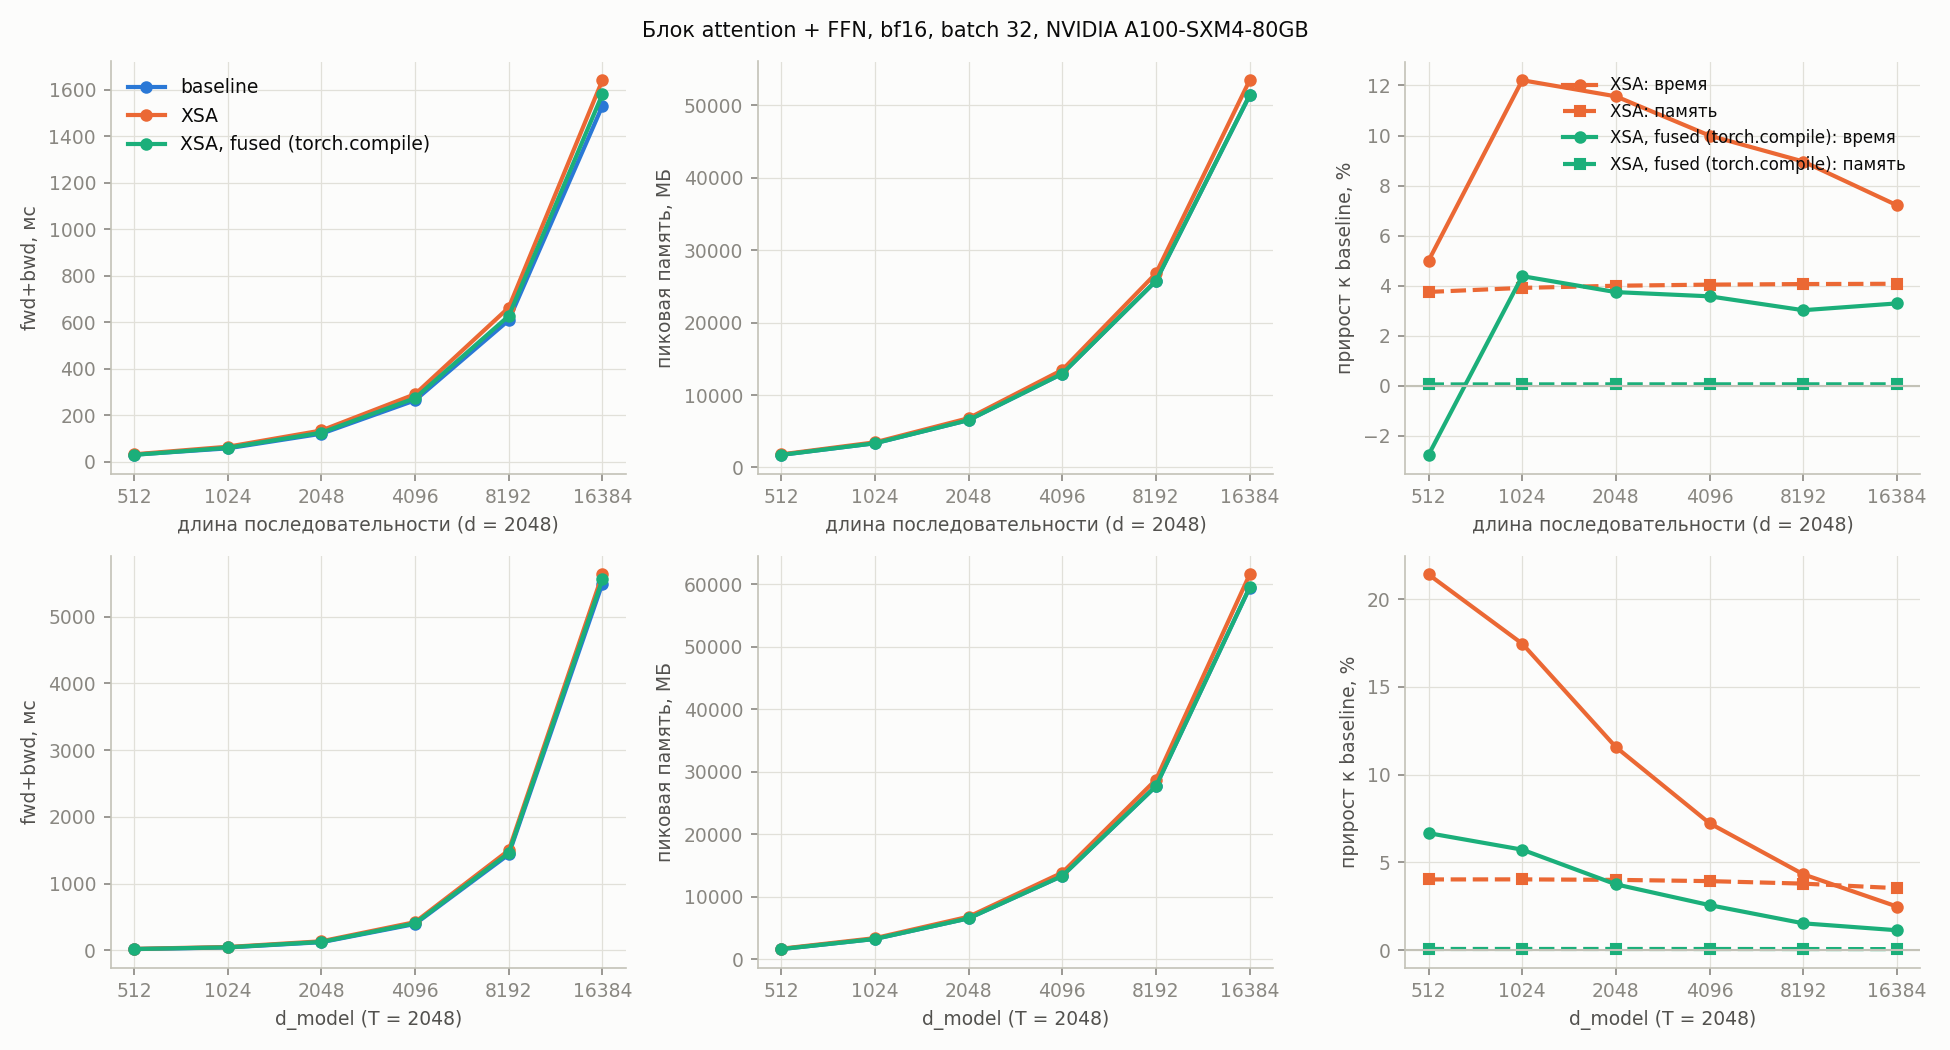

Сама операция XSA, fwd+bwd (GB/s посчитаны по минимальному трафику, 8 проходов):
                  ms              GB/s          % от блока         
variant     op_eager op_fused op_eager op_fused   op_eager op_fused
T     d                                                            
512   2048      2.99     0.90   179.55   593.53       9.79     2.96
1024  2048      5.76     1.56   186.53   690.08       9.99     2.70
2048  512       2.99     1.03   179.85   520.88      17.47     6.03
      1024      5.76     1.53   186.51   699.61      13.87     3.70
      2048     11.31     2.88   189.88   746.62       9.38     2.39
      4096     22.38     5.54   191.90   775.54       5.69     1.41
      8192     44.60    10.99   192.61   781.51       3.11     0.77
      16384    89.13    22.07   192.75   778.43       1.62     0.40
4096  2048     22.40     5.53   191.73   777.20       8.48     2.09
8192  2048     44.61    11.04   192.55   778.36       7.33     1.81
16384 2048     88.99    21.91   193

In [8]:
def plot_bench(bench):
    fig, axes = plt.subplots(2, 3, figsize=(13, 7))
    for row, (points, key, label) in enumerate([(BENCH_SEQ, "T", "длина последовательности (d = 2048)"),
                                                (BENCH_DIM, "d", "d_model (T = 2048)")]):
        sub = bench.merge(pd.DataFrame(points, columns=["T", "d"]))
        piv = {m: sub.pivot(index=key, columns="variant", values=m) for m in ("ms", "peak_mb")}
        for col, (metric, ylabel) in enumerate([("ms", "fwd+bwd, мс"), ("peak_mb", "пиковая память, МБ")]):
            ax = axes[row, col]
            for v in BENCH_VARIANTS:
                ax.plot(piv[metric].index, piv[metric][v], marker="o", color=COLORS[v], label=LABELS[v])
            ax.set(xlabel=label, ylabel=ylabel)
            log2_axis(ax, list(piv[metric].index))
        ax = axes[row, 2]
        for v in BENCH_VARIANTS[1:]:
            ax.plot(piv["ms"].index, 100 * (piv["ms"][v] / piv["ms"]["base"] - 1), marker="o", color=COLORS[v],
                    label=f"{LABELS[v]}: время")
            ax.plot(piv["peak_mb"].index, 100 * (piv["peak_mb"][v] / piv["peak_mb"]["base"] - 1), marker="s",
                    linestyle="--", color=COLORS[v], label=f"{LABELS[v]}: память")
        ax.axhline(0, color="#c3c2b7", linewidth=1)
        ax.set(xlabel=label, ylabel="прирост к baseline, %")
        log2_axis(ax, list(piv["ms"].index))
    axes[0, 0].legend()
    axes[0, 2].legend(fontsize=8)
    fig.suptitle(f"Блок attention + FFN, bf16, batch {BENCH_B}, {GPU}", fontsize=10)
    save(fig, "fig2_overhead.png")


plot_bench(bench)
ops = bench[bench.variant.str.startswith("op_")].copy()
ops["GB/s"] = 8 * 2 * BENCH_B * ops["T"] * ops["d"] / (ops["ms"] / 1000) / 1e9
blocks = bench[bench.variant == "base"][["T", "d", "ms"]].rename(columns={"ms": "block_ms"})
ops = ops.merge(blocks, on=["T", "d"])
ops["% от блока"] = 100 * ops["ms"] / ops["block_ms"]
print("Сама операция XSA, fwd+bwd (GB/s посчитаны по минимальному трафику, 8 проходов):")
print(ops.pivot(index=["T", "d"], columns="variant", values=["ms", "GB/s", "% от блока"]).round(2).to_string())

## 5. Attention similarity bias (рис. 1)

По слоям, в среднем по головам и текстам:

- `vv`: косинус между value разных позиций;
- `a_self`: вес внимания на себя $a_{ii}$, $i > 1$;
- `yv`: косинус между выходом внимания $y_i$ и $v_i$;
- `a_first`: вес внимания на первый токен, в статье его нет.

Модель автора не выложена. Ближе всего к ней Pythia-1.4B: 24 слоя, RoPE, контекст 2048. Ещё Pythia-160M, GPT-2 и GPT-2 medium. Тексты: 64 последовательности из валидации FineWeb.

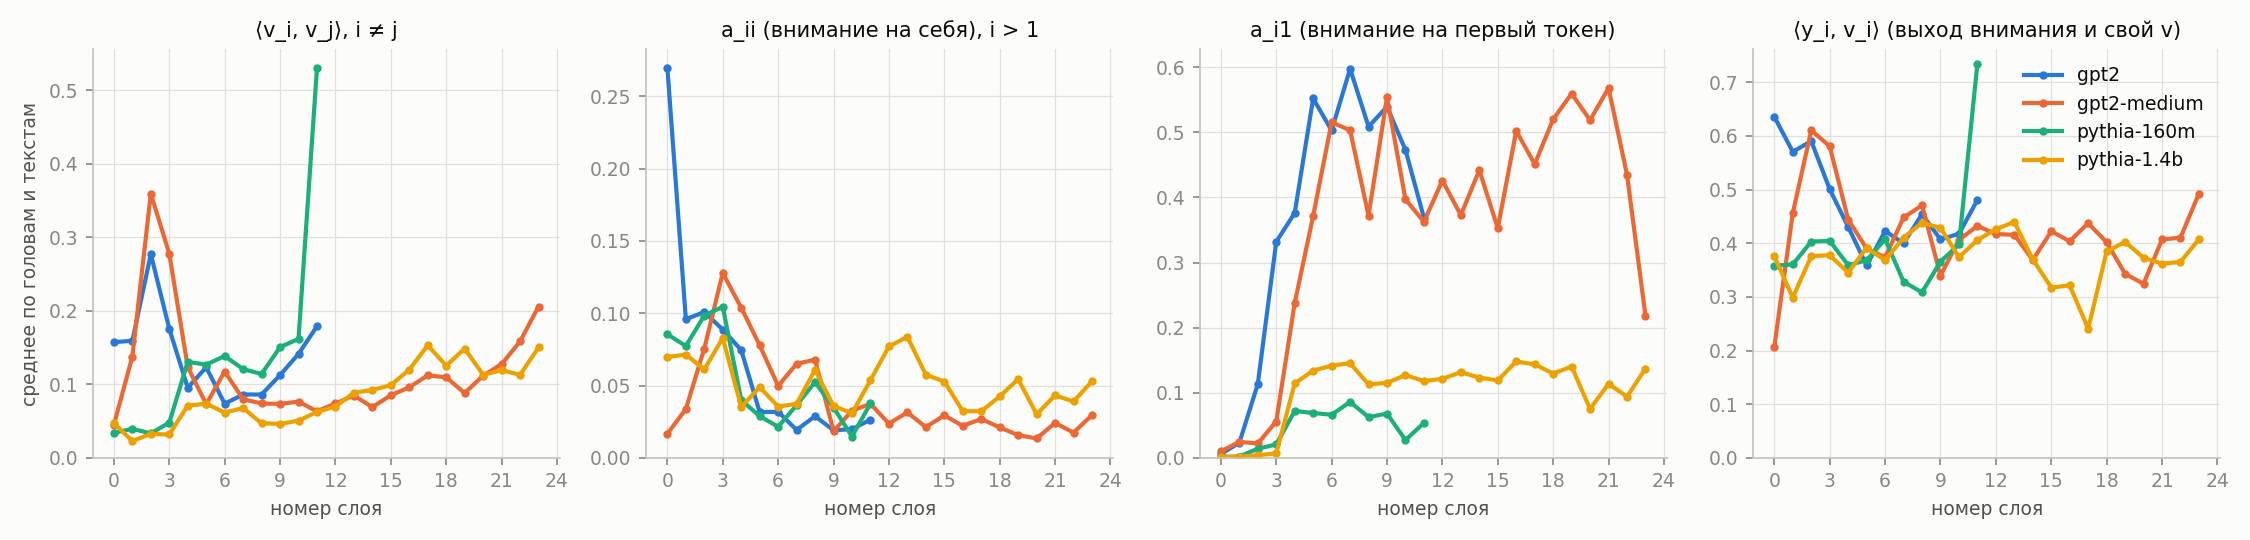

In [9]:
HF_MODELS = {   # модель: (архитектура, длина последовательности)
    "gpt2": ("gpt2", 1024),
    "gpt2-medium": ("gpt2", 1024),
    "EleutherAI/pythia-160m": ("neox", 2048),
    "EleutherAI/pythia-1.4b": ("neox", 2048),
}
HF_N_SEQ = 64
ENC = tiktoken.get_encoding("gpt2")


@torch.no_grad()
def hf_bias_stats(name, kind, T, n_seq=HF_N_SEQ, batch=2):
    from transformers import AutoModelForCausalLM, AutoTokenizer
    # token=False: модели публичные, без этого Colab спрашивает доступ к секрету HF_TOKEN
    model = AutoModelForCausalLM.from_pretrained(name, dtype=torch.bfloat16, attn_implementation="eager", token=False)
    model.to(DEVICE).eval()
    H = model.config.num_attention_heads
    D = model.config.hidden_size
    dh = D // H
    if kind == "gpt2":
        blocks = model.transformer.h
        qkv_mods, out_mods = [b.attn.c_attn for b in blocks], [b.attn.c_proj for b in blocks]
        ids = val_tokens[STATS_OFFSET: STATS_OFFSET + n_seq * T].astype(np.int64)
    else:
        blocks = model.gpt_neox.layers
        qkv_mods, out_mods = [b.attention.query_key_value for b in blocks], [b.attention.dense for b in blocks]
        text = ENC.decode(val_tokens[STATS_OFFSET: STATS_OFFSET + 2 * n_seq * T].tolist())
        ids = AutoTokenizer.from_pretrained(name, token=False)(text)["input_ids"][: n_seq * T]
    ids = torch.tensor(ids).view(n_seq, T)
    L = len(blocks)
    acc = {k: np.zeros(L) for k in ("vv", "a_self", "a_first", "yv")}
    values = {}

    def on_qkv(i):
        def hook(mod, inp, out):
            B_, T_, _ = out.shape
            v = out[..., 2 * D:].reshape(B_, T_, H, dh) if kind == "gpt2" else out.view(B_, T_, H, 3 * dh)[..., 2 * dh:]
            values[i] = v.transpose(1, 2).float()
        return hook

    def on_out(i):
        def hook(mod, args):
            v = values.pop(i)
            B_, _, T_, _ = v.shape
            y = args[0].reshape(B_, T_, H, dh).transpose(1, 2).float()
            s = F.normalize(v, dim=-1).sum(2)
            acc["vv"][i] += (((s * s).sum(-1) - T_) / (T_ * (T_ - 1))).mean().item()
            acc["yv"][i] += F.cosine_similarity(y, v, dim=-1)[..., 1:].mean().item()
        return hook

    handles = [m.register_forward_hook(on_qkv(i)) for i, m in enumerate(qkv_mods)]
    handles += [m.register_forward_pre_hook(on_out(i)) for i, m in enumerate(out_mods)]
    n = 0
    try:
        for i in range(0, n_seq, batch):
            out = model(ids[i:i + batch].to(DEVICE), output_attentions=True)
            if out.attentions is None or out.attentions[0] is None:
                acc["a_self"][:] = acc["a_first"][:] = np.nan
            else:
                for l, a in enumerate(out.attentions):
                    acc["a_self"][l] += a.diagonal(dim1=-2, dim2=-1)[..., 1:].float().mean().item()
                    acc["a_first"][l] += a[..., 1:, 0].float().mean().item()
            n += 1
    finally:
        for h in handles:
            h.remove()
        del model
        gc.collect()
        if DEVICE == "cuda":
            torch.cuda.empty_cache()
    return {k: (v / n).tolist() for k, v in acc.items()}


def run_hf_bias():
    path = os.path.join(RESULTS, "bias_pretrained.json")
    res = json.load(open(path)) if os.path.exists(path) else {}
    for name, (kind, T) in HF_MODELS.items():
        if name in res:
            continue
        try:
            res[name] = hf_bias_stats(name, kind, T)
            print(f"{name}: yv по слоям {np.round(res[name]['yv'], 2).tolist()}")
        except Exception as e:
            print(f"{name}: не получилось ({type(e).__name__}: {e})")
        with open(path, "w") as f:
            json.dump(res, f)
    return res


STAT_TITLES = {
    "vv": "⟨v_i, v_j⟩, i ≠ j",
    "a_self": "a_ii (внимание на себя), i > 1",
    "a_first": "a_i1 (внимание на первый токен)",
    "yv": "⟨y_i, v_i⟩ (выход внимания и свой v)",
}


def plot_hf_bias(res):
    fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
    for ax, key in zip(axes, STAT_TITLES):
        for color, (name, r) in zip(SERIES, res.items()):
            ax.plot(range(len(r[key])), r[key], marker="o", markersize=3, color=color, label=name.split("/")[-1])
        ax.set(title=STAT_TITLES[key], xlabel="номер слоя")
        ax.set_ylim(bottom=0)
        ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    axes[0].set_ylabel("среднее по головам и текстам")
    axes[-1].legend()
    save(fig, "fig1_bias_pretrained.png")


hf_bias = run_hf_bias()
plot_hf_bias(hf_bias)

## 6. Обучение

AdamW (β 0.9/0.95, weight decay 0.1), warmup 5% шагов, косинус до 0.1·LR, клиппинг 1.0, bf16, `torch.compile`. 131k токенов на шаг и 100M на запуск, у автора 0.5M и 100B.

Для основной конфигурации (S, T=1024, LR 2e-3) ещё считаются статистики внимания, LAMBADA и HellaSwag. Модель маленькая, на обеих задачах она около случайного уровня.

In [10]:
LAMBADA_URL = "https://openaipublic.blob.core.windows.net/gpt-2/data/lambada_test.jsonl"
HELLASWAG_URL = "https://huggingface.co/datasets/Rowan/hellaswag/resolve/main/data/validation-00000-of-00001.parquet"


def pad_batch(seqs):
    x = torch.zeros(len(seqs), max(map(len, seqs)), dtype=torch.long)
    for i, s in enumerate(seqs):
        x[i, :len(s)] = torch.tensor(s)
    return x.to(DEVICE)


@torch.no_grad()
def eval_lambada(model, batch=64, limit=None):
    with open(download(LAMBADA_URL, "lambada_test.jsonl")) as f:
        docs = [json.loads(line)["text"] for line in f][:limit]
    T = model.cfg.seq_len
    model.eval()
    correct = 0
    for i in range(0, len(docs), batch):
        items = []
        for text in docs[i:i + batch]:
            ctx, word = text.rsplit(" ", 1)
            target = ENC.encode(" " + word)
            items.append(((ENC.encode(ctx) + target)[-T:], len(target)))
        with amp():
            pred = model(pad_batch([s for s, _ in items])).argmax(-1).cpu()
        for j, (s, k) in enumerate(items):
            correct += pred[j, len(s) - k - 1: len(s) - 1].tolist() == s[-k:]
    model.train()
    return correct / len(docs)


@torch.no_grad()
def eval_hellaswag(model, batch=16, limit=None):
    df = pd.read_parquet(download(HELLASWAG_URL, "hellaswag_val.parquet"))[:limit]
    model.eval()
    correct = 0
    for i in range(0, len(df), batch):
        rows, spans, labels = [], [], []
        for _, d in df.iloc[i:i + batch].iterrows():
            ctx = ENC.encode(d["ctx"])
            for ending in d["endings"]:
                end = ENC.encode(" " + ending)
                rows.append(ctx + end)
                spans.append((len(ctx), len(ctx) + len(end)))
            labels.append(int(d["label"]))
        x = pad_batch(rows)
        with amp():
            logits = model(x)
        loss = F.cross_entropy(logits[:, :-1].float().transpose(1, 2), x[:, 1:], reduction="none")
        mask = torch.zeros_like(loss)
        for j, (a, b) in enumerate(spans):
            mask[j, a - 1:b - 1] = 1
        avg = (loss * mask).sum(1) / mask.sum(1)
        correct += (avg.view(-1, 4).argmin(1).cpu() == torch.tensor(labels)).sum().item()
    model.train()
    return correct / len(df)


@torch.no_grad()
def attention_stats(model, T, n_seq=32, batch=4):
    model.eval()
    for b in model.blocks:
        b.attn.stats = {k: [] for k in STAT_KEYS}
    for i in range(0, n_seq, batch):
        x, _ = get_batch(val_tokens, STATS_OFFSET + i * T, batch, T)
        model(x)
    out = {k: [float(np.mean(b.attn.stats[k])) if b.attn.stats[k] else None for b in model.blocks] for k in STAT_KEYS}
    for b in model.blocks:
        b.attn.stats = None
    model.train()
    return out


@torch.no_grad()
def evaluate(model, T, n_tokens):
    model.eval()
    B = max(1, TRAIN["micro_tokens"] // T)
    losses = []
    for pos in range(0, n_tokens - B * T + 1, B * T):
        x, y = get_batch(val_tokens, pos, B, T)
        with amp():
            losses.append(model(x, y))
    model.train()
    return torch.stack(losses).mean().item()


class StepTimer:
    """Суммарное время шагов без компиляции и валидации."""

    def __init__(self, skip):
        self.skip, self.total, self.n, self.t0, self.s0 = skip, 0.0, 0, None, 0

    def start(self, step):
        sync()
        self.t0, self.s0 = time.perf_counter(), step

    def stop(self, step):
        if self.t0 is not None:
            sync()
            self.total += time.perf_counter() - self.t0
            self.n += step - self.s0
            self.t0 = None

    @property
    def ms(self):
        return 1000 * self.total / self.n if self.n else float("nan")


def lr_at(step, steps, lr):
    warmup = max(1, int(TRAIN["warmup_frac"] * steps))
    if step < warmup:
        return lr * (step + 1) / warmup
    p = (step - warmup) / max(1, steps - warmup)
    return lr * (TRAIN["min_lr_frac"] + (1 - TRAIN["min_lr_frac"]) * 0.5 * (1 + math.cos(math.pi * p)))


def train(run):
    path = os.path.join(RESULTS, "runs", run.name + ".json")
    if os.path.exists(path):
        with open(path) as f:
            return json.load(f)
    torch._dynamo.reset()
    torch.manual_seed(run.seed)
    n_layer, n_embd, n_head = SIZES[run.size]
    cfg = GPTConfig(n_layer=n_layer, n_embd=n_embd, n_head=n_head, seq_len=run.seq_len,
                    xsa_layers=xsa_layers(run.variant, n_layer), n_sinks=run.n_sinks)
    model = GPT(cfg).to(DEVICE)
    n_total, n_body = count_params(model)
    params = list(model.named_parameters())
    opt = torch.optim.AdamW(
        [{"params": [p for n, p in params if p.dim() >= 2 and n != "sinks"], "weight_decay": TRAIN["weight_decay"]},
         {"params": [p for n, p in params if p.dim() < 2 or n == "sinks"], "weight_decay": 0.0}],
        lr=run.lr, betas=TRAIN["betas"], fused=DEVICE == "cuda")
    cmodel = torch.compile(model) if COMPILE else model

    T = run.seq_len
    B = TRAIN["micro_tokens"] // T
    accum = TRAIN["batch_tokens"] // TRAIN["micro_tokens"]
    steps = run.tokens // TRAIN["batch_tokens"]
    pos = run.seed * run.tokens
    log = {"train_loss": [], "val_step": [], "val_loss": []}
    timer = StepTimer(TRAIN["timing_skip"])
    if DEVICE == "cuda":
        torch.cuda.reset_peak_memory_stats()
    t_start = time.perf_counter()
    for step in range(steps):
        if timer.t0 is None and step >= timer.skip:
            timer.start(step)
        for g in opt.param_groups:
            g["lr"] = lr_at(step, steps, run.lr)
        loss_sum = torch.zeros((), device=DEVICE)
        for _ in range(accum):
            x, y = get_batch(train_tokens, pos, B, T)
            pos += B * T
            with amp():
                loss = cmodel(x, y)
            (loss / accum).backward()
            loss_sum += loss.detach()
        torch.nn.utils.clip_grad_norm_(model.parameters(), TRAIN["grad_clip"])
        opt.step()
        opt.zero_grad(set_to_none=True)
        log["train_loss"].append(loss_sum / accum)
        done = step + 1
        if done % TRAIN["eval_every"] == 0 or done == steps:
            timer.stop(done)
            log["val_step"].append(done)
            log["val_loss"].append(evaluate(cmodel, T, TRAIN["eval_tokens"]))
            left = (time.perf_counter() - t_start) / done * (steps - done) / 60
            print(f"  шаг {done:5d}/{steps} | train {log['train_loss'][-1].item():.4f} | "
                  f"val {log['val_loss'][-1]:.4f} | {timer.ms:.0f} мс/шаг | осталось ~{left:.1f} мин")

    log["train_loss"] = torch.stack(log["train_loss"]).tolist()
    result = {
        "name": run.name, "run": asdict(run), "params_total": n_total, "params_body": n_body,
        "steps": steps, "batch_tokens": TRAIN["batch_tokens"],
        "final_train": float(np.mean(log["train_loss"][-max(1, steps // 20):])),  # среднее за последние 5% шагов
        "final_val": evaluate(cmodel, T, TRAIN["final_eval_tokens"]),
        "step_ms": timer.ms,
        "tokens_per_s": TRAIN["batch_tokens"] / timer.ms * 1000,
        "peak_mem_gb": torch.cuda.max_memory_allocated() / 2**30 if DEVICE == "cuda" else None,
        "wall_min": (time.perf_counter() - t_start) / 60,
        "gpu": GPU, "torch": torch.__version__, "log": log,
    }
    if run.is_main and run.n_sinks == 0:
        result["stats"] = attention_stats(model, T)
        result["lambada"] = eval_lambada(model)
        result["hellaswag"] = eval_hellaswag(model)
        if run.seed == 0:
            torch.save({k: v.to(torch.bfloat16) for k, v in model.state_dict().items()},
                       os.path.join(RESULTS, "ckpt", run.name + ".pt"))
    with open(path + ".tmp", "w") as f:
        json.dump(result, f)
    os.replace(path + ".tmp", path)
    del model, cmodel, opt
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    return result

In [11]:
t0 = time.perf_counter()
trained = 0
for i, run in enumerate(PLAN, 1):
    print(f"[{i}/{len(PLAN)}] {run.name} | прошло {(time.perf_counter() - t0) / 60:.0f} мин")
    cached = os.path.exists(os.path.join(RESULTS, "runs", run.name + ".json"))
    r = train(run)
    trained += not cached
    extra = f", LAMBADA {r['lambada']:.3f}, HellaSwag {r['hellaswag']:.3f}" if "lambada" in r else ""
    print(f"  итог: val {r['final_val']:.4f}, train {r['final_train']:.4f}, {r['step_ms']:.0f} мс/шаг{extra}")
    if trained:
        left = sum(not os.path.exists(os.path.join(RESULTS, "runs", p.name + ".json")) for p in PLAN)
        print(f"  до конца плана примерно {(time.perf_counter() - t0) / trained * left / 60:.0f} мин")

[1/33] S_T1024_lr0.002_sink0_s0_base | прошло 0 мин
  итог: val 4.9937, train 5.0013, 196 мс/шаг, LAMBADA 0.001, HellaSwag 0.242
[2/33] S_T1024_lr0.002_sink0_s0_xsa | прошло 0 мин
  итог: val 4.8220, train 4.8303, 202 мс/шаг, LAMBADA 0.007, HellaSwag 0.243
[3/33] S_T1024_lr0.002_sink0_s0_xsa_half | прошло 0 мин
  шаг   100/762 | train 6.7071 | val 6.6449 | 196 мс/шаг | осталось ~4.8 мин
  шаг   200/762 | train 5.9408 | val 5.9990 | 197 мс/шаг | осталось ~3.0 мин
  шаг   300/762 | train 5.6749 | val 5.6272 | 198 мс/шаг | осталось ~2.2 мин
  шаг   400/762 | train 5.2542 | val 5.3812 | 198 мс/шаг | осталось ~1.6 мин
  шаг   500/762 | train 5.1753 | val 5.1935 | 198 мс/шаг | осталось ~1.1 мин
  шаг   600/762 | train 5.0705 | val 5.0689 | 198 мс/шаг | осталось ~0.7 мин
  шаг   700/762 | train 4.9640 | val 4.9855 | 199 мс/шаг | осталось ~0.3 мин
  шаг   762/762 | train 4.7999 | val 4.9533 | 199 мс/шаг | осталось ~0.0 мин
скачиваю lambada_test.jsonl
скачиваю hellaswag_val.parquet
  итог: val 

## 7. Результаты

Δ = loss(XSA) − loss(base) внутри пары с одним сидом, Δ < 0 значит, что XSA лучше. `wins`: в скольких сидах XSA лучше; `p`: t-тест для среднего Δ = 0.

In [12]:
CONFIG = ["size", "seq_len", "lr", "n_sinks"]


def load_runs():
    runs = {}
    for p in sorted(glob.glob(os.path.join(RESULTS, "runs", "*.json"))):
        with open(p) as f:
            r = json.load(f)
        runs[r["name"]] = r
    rows = [dict(r["run"], name=name, final_val=r["final_val"], final_train=r["final_train"],
                 step_ms=r["step_ms"], tokens_per_s=r["tokens_per_s"], peak_mem_gb=r["peak_mem_gb"],
                 params_total=r["params_total"], lambada=r.get("lambada"), hellaswag=r.get("hellaswag"))
            for name, r in runs.items()]
    return runs, pd.DataFrame(rows)


def paired(df, metric, lower_is_better=True):
    key = CONFIG + ["seed"]
    base = df[df.variant == "base"][key + [metric]].rename(columns={metric: "base"})
    out = []
    for variant in ("xsa", "xsa_half"):
        m = df[df.variant == variant][key + [metric]].merge(base, on=key).dropna()
        m["delta"] = m[metric] - m["base"]
        for cfg, g in m.groupby(CONFIG):
            n = len(g)
            wins = (g["delta"] < 0).sum() if lower_is_better else (g["delta"] > 0).sum()
            out.append(dict(zip(CONFIG, cfg), variant=variant, seeds=n, base=g["base"].mean(), xsa=g[metric].mean(),
                            delta=g["delta"].mean(), delta_std=g["delta"].std(ddof=1) if n > 1 else np.nan,
                            wins=f"{wins}/{n}", p=stats.ttest_1samp(g["delta"], 0).pvalue if n > 2 else np.nan))
    return pd.DataFrame(out)


RUNS, df = load_runs()
print(f"всего запусков: {len(df)}")
tables = {}
for metric, lower in (("final_val", True), ("final_train", True), ("step_ms", True), ("lambada", False), ("hellaswag", False)):
    t = paired(df.dropna(subset=[metric]), metric, lower)
    if len(t):
        tables[metric] = t
        t.to_csv(os.path.join(RESULTS, f"paired_{metric}.csv"), index=False)
        print(f"\n=== {metric} ===")
        print(t.to_string(index=False, float_format=lambda x: f"{x:.4g}"))

всего запусков: 33

=== final_val ===
size  seq_len    lr  n_sinks  variant  seeds  base   xsa    delta  delta_std wins        p
   M     1024 0.002        0      xsa      1  5.09 4.546  -0.5441        NaN  1/1      NaN
   S      256 0.002        0      xsa      3 5.069 4.837  -0.2323    0.02252  3/3 0.003119
   S     1024 0.001        0      xsa      1 5.166 5.071 -0.09533        NaN  1/1      NaN
   S     1024 0.002        0      xsa      3 5.004 4.776  -0.2279    0.06086  3/3  0.02295
   S     1024 0.002        1      xsa      1 5.009 4.802  -0.2073        NaN  1/1      NaN
   S     1024 0.002        4      xsa      1 5.094 4.823  -0.2703        NaN  1/1      NaN
   S     1024 0.004        0      xsa      1 5.458 4.831  -0.6269        NaN  1/1      NaN
   S     4096 0.002        0      xsa      3 5.036 4.796  -0.2399    0.04944  3/3  0.01386
  XS     1024 0.002        0      xsa      1 5.239 5.157 -0.08266        NaN  1/1      NaN
   S     1024 0.002        0 xsa_half      3 5.004 4

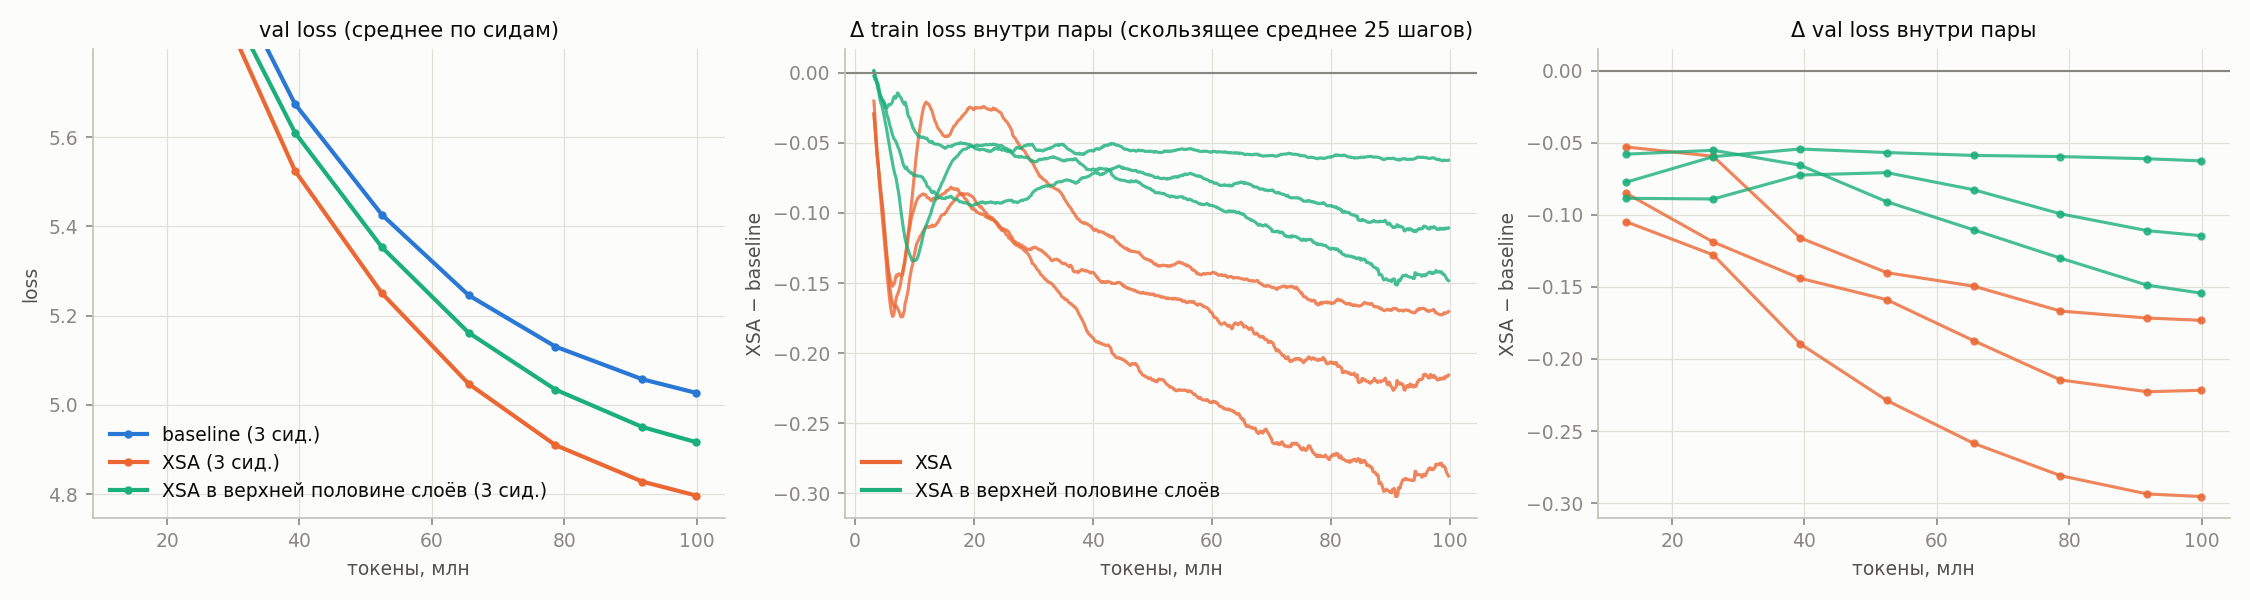

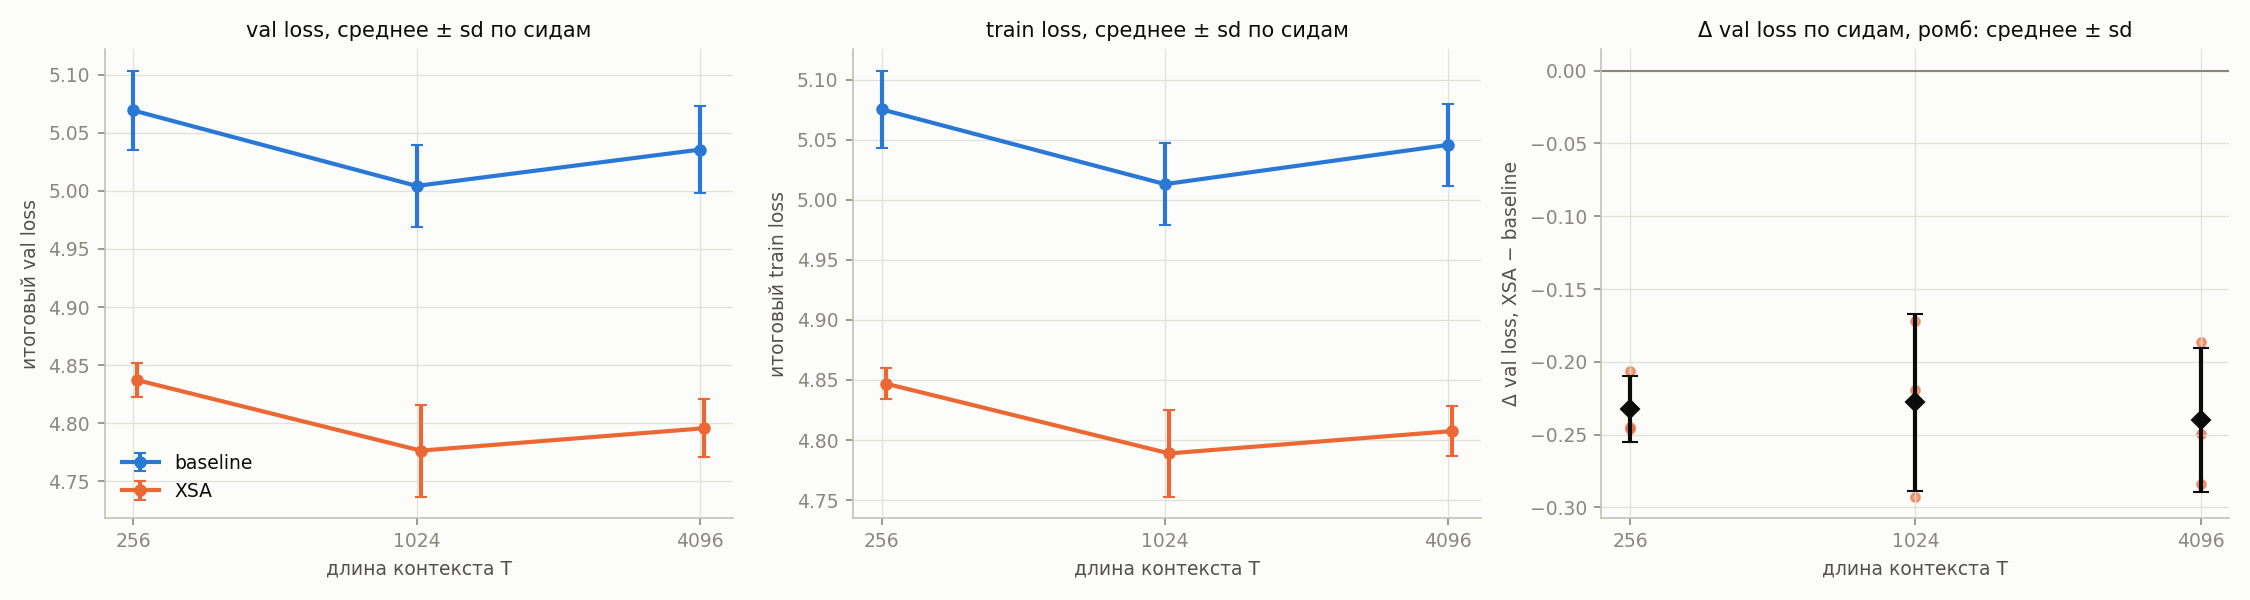

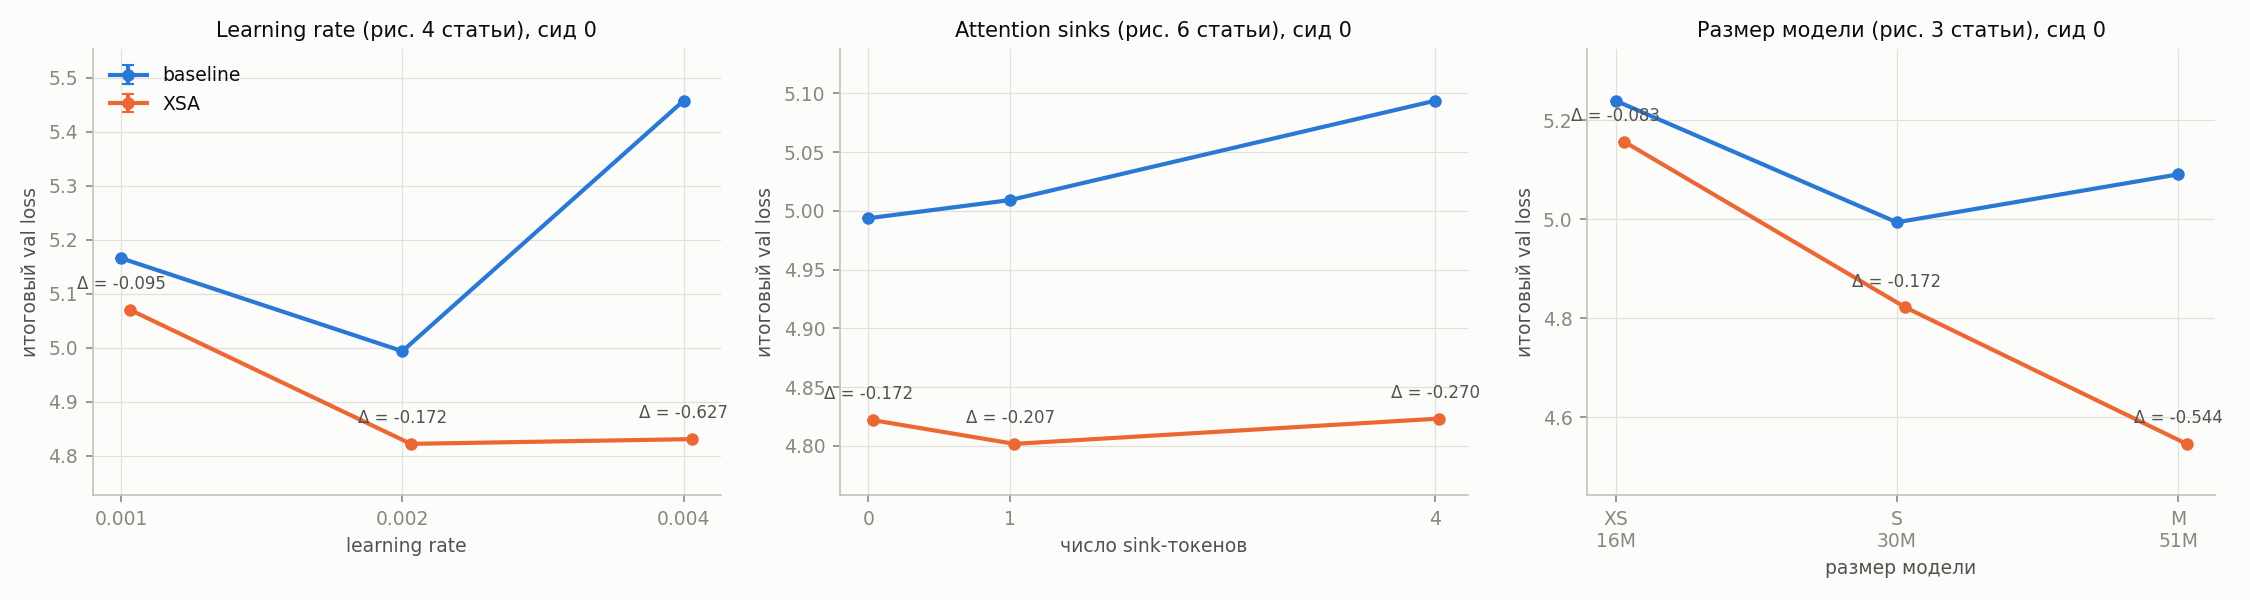

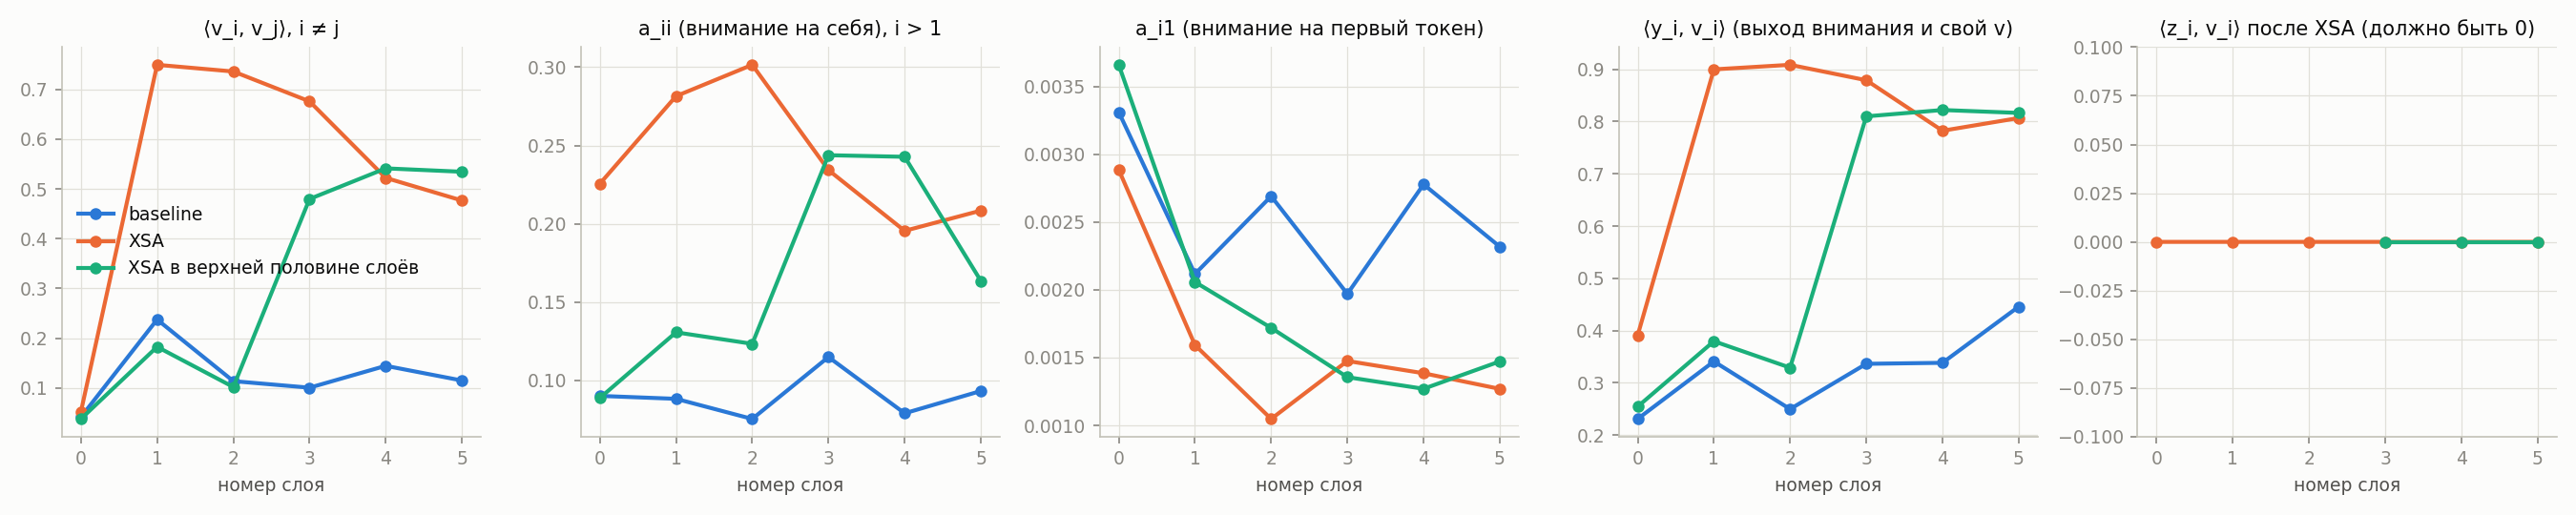

In [13]:
def runs_of(variant, **cfg):
    if "size_idx" in cfg:
        cfg["size"] = [s for s in SIZES if runs_of("base", size=s, seed=0)][cfg.pop("size_idx")]
    want = dict(size="S", seq_len=1024, lr=TRAIN["lr"], n_sinks=0) | cfg
    return [r for r in RUNS.values() if r["run"]["variant"] == variant
            and all(r["run"][k] == v for k, v in want.items())]


def smooth(x, k=25):
    x = np.asarray(x, dtype=float)
    return np.convolve(x, np.ones(k) / k, mode="valid") if len(x) > k else x


def plot_curves():
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    variants = [v for v in ("base", "xsa", "xsa_half") if runs_of(v)]
    base = {r["run"]["seed"]: r for r in runs_of("base")}
    for v in variants:
        rs = runs_of(v)
        tok = np.array(rs[0]["log"]["val_step"]) * rs[0]["batch_tokens"] / 1e6
        val = np.mean([r["log"]["val_loss"] for r in rs], axis=0)
        axes[0].plot(tok, val, marker="o", markersize=3, color=COLORS[v], label=f"{LABELS[v]} ({len(rs)} сид.)")
        if v == "base":
            continue
        for r in rs:
            b = base.get(r["run"]["seed"])
            if b is None:
                continue
            d = smooth(np.array(r["log"]["train_loss"]) - np.array(b["log"]["train_loss"]))
            x = (np.arange(len(d)) + (len(r["log"]["train_loss"]) - len(d))) * r["batch_tokens"] / 1e6
            axes[1].plot(x, d, color=COLORS[v], alpha=0.8, linewidth=1.5)
            dv = np.array(r["log"]["val_loss"]) - np.array(b["log"]["val_loss"])
            axes[2].plot(tok, dv, marker="o", markersize=3, color=COLORS[v], alpha=0.8, linewidth=1.5)
    lo = min(min(np.mean([r["log"]["val_loss"] for r in runs_of(v)], axis=0)) for v in variants)
    axes[0].set(ylim=(lo - 0.05, lo + 1.0), title="val loss (среднее по сидам)",
                xlabel="токены, млн", ylabel="loss")
    axes[0].legend()
    for ax, title in ((axes[1], "Δ train loss внутри пары (скользящее среднее 25 шагов)"),
                      (axes[2], "Δ val loss внутри пары")):
        ax.axhline(0, color="#898781", linewidth=1)
        ax.set(title=title, xlabel="токены, млн", ylabel="XSA − baseline")
    for v in variants[1:]:
        axes[1].plot([], [], color=COLORS[v], label=LABELS[v])
    axes[1].legend()
    save(fig, "fig3_loss.png")


def final(variant, metric="final_val", **cfg):
    vals = [r[metric] for r in runs_of(variant, **cfg)]
    return (np.mean(vals), np.std(vals, ddof=1) if len(vals) > 1 else 0.0, len(vals)) if vals else (np.nan, np.nan, 0)


def plot_sweep(ax, xs, key, xlabel, metric="final_val", log=True, annotate=False, **cfg):
    for v, shift in (("base", 0.0), ("xsa", 0.03)):
        pts = [(x * 2**shift if log else x + shift, *final(v, metric, **{key: x}, **cfg)) for x in xs]
        pts = [p for p in pts if p[3]]
        if pts:
            x, m, s, _ = zip(*pts)
            ax.errorbar(x, m, yerr=s, marker="o", color=COLORS[v], label=LABELS[v], capsize=3)
    ax.set(xlabel=xlabel, ylabel="итоговый val loss" if metric == "final_val" else "итоговый train loss")
    if log:
        log2_axis(ax, xs)
    else:
        ax.set_xticks(xs, [f"{x:g}" for x in xs])
    if annotate:
        annotate_delta(ax, xs, key, **cfg)
        ax.margins(y=0.15)


def annotate_delta(ax, xs, key, **cfg):
    for x in xs:
        base = {r["run"]["seed"]: r["final_val"] for r in runs_of("base", **{key: x}, **cfg)}
        ds = [r["final_val"] - base[r["run"]["seed"]] for r in runs_of("xsa", **{key: x}, **cfg) if r["run"]["seed"] in base]
        if ds:
            ax.annotate(f"Δ = {np.mean(ds):+.3f}", (x, final("xsa", **{key: x}, **cfg)[0]), textcoords="offset points",
                        xytext=(0, 10), ha="center", fontsize=8, color="#52514e")


def plot_delta(ax, xs, key, xlabel, log=True):
    for x in xs:
        base = {r["run"]["seed"]: r["final_val"] for r in runs_of("base", **{key: x})}
        ds = [r["final_val"] - base[r["run"]["seed"]] for r in runs_of("xsa", **{key: x}) if r["run"]["seed"] in base]
        if ds:
            ax.scatter([x] * len(ds), ds, color=COLORS["xsa"], s=18, alpha=0.6)
            ax.errorbar([x], [np.mean(ds)], yerr=[np.std(ds, ddof=1) if len(ds) > 1 else 0], marker="D",
                        color="#0b0b0b", capsize=4, markersize=6)
    ax.axhline(0, color="#898781", linewidth=1)
    ax.set(xlabel=xlabel, ylabel="Δ val loss, XSA − baseline", title="Δ val loss по сидам, ромб: среднее ± sd")
    if log:
        log2_axis(ax, xs)
    else:
        ax.set_xticks(xs, [f"{x:g}" for x in xs])


def plot_context():
    xs = sorted({r["run"]["seq_len"] for r in RUNS.values() if r["run"]["size"] == "S" and r["run"]["lr"] == TRAIN["lr"]
                 and r["run"]["n_sinks"] == 0})
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    plot_sweep(axes[0], xs, "seq_len", "длина контекста T")
    plot_sweep(axes[1], xs, "seq_len", "длина контекста T", metric="final_train")
    plot_delta(axes[2], xs, "seq_len", "длина контекста T")
    axes[0].legend()
    axes[0].set_title("val loss, среднее ± sd по сидам")
    axes[1].set_title("train loss, среднее ± sd по сидам")
    save(fig, "fig5_context.png")


def plot_robustness():
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    plot_sweep(axes[0], [1e-3, 2e-3, 4e-3], "lr", "learning rate", annotate=True, seed=0)
    axes[0].set_title("Learning rate (рис. 4 статьи), сид 0")
    plot_sweep(axes[1], [0, 1, 4], "n_sinks", "число sink-токенов", log=False, annotate=True, seed=0)
    axes[1].set_title("Attention sinks (рис. 6 статьи), сид 0")
    sizes = [s for s in SIZES if runs_of("base", size=s, seed=0)]
    plot_sweep(axes[2], list(range(len(sizes))), "size_idx", "размер модели", log=False, annotate=True, seed=0)
    labels = [f"{s}\n{runs_of('base', size=s, seed=0)[0]['params_total'] / 1e6:.0f}M" for s in sizes]
    axes[2].set_xticks(range(len(sizes)), labels)
    axes[2].set_title("Размер модели (рис. 3 статьи), сид 0")
    axes[0].legend()
    save(fig, "fig4_6_robustness.png")


def plot_stats():
    keys = ["vv", "a_self", "a_first", "yv"]
    fig, axes = plt.subplots(1, 5, figsize=(18, 3.6))
    for v in ("base", "xsa", "xsa_half"):
        rs = [r for r in runs_of(v) if "stats" in r]
        if not rs:
            continue
        for ax, key in zip(axes, keys + ["zv"]):
            vals = np.array([[np.nan if x is None else x for x in r["stats"][key]] for r in rs], dtype=float)
            if np.isnan(vals).all():
                continue
            ax.plot(np.arange(vals.shape[1]), np.nanmean(vals, axis=0), marker="o", color=COLORS[v], label=LABELS[v])
    for ax, key in zip(axes, keys):
        ax.set(title=STAT_TITLES[key], xlabel="номер слоя")
    axes[4].set(title="⟨z_i, v_i⟩ после XSA (должно быть 0)", xlabel="номер слоя", ylim=(-0.1, 0.1))
    for ax in axes:
        ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    axes[0].legend()
    save(fig, "fig1b_bias_ours.png")


plot_curves()
plot_context()
plot_robustness()
plot_stats()

In [14]:
cols = ["variant", "seed", "final_val", "final_train", "step_ms", "tokens_per_s", "peak_mem_gb", "lambada", "hellaswag"]
main = df[(df["size"] == "S") & (df.seq_len == 1024) & (df.lr == TRAIN["lr"]) & (df.n_sinks == 0)]
print("Основная конфигурация (S, T=1024):")
print(main[cols].sort_values(["variant", "seed"]).to_string(index=False, float_format=lambda x: f"{x:.4f}"))
speed = df[(df["size"] == "S") & (df.n_sinks == 0)].groupby(["seq_len", "variant"])[["step_ms", "tokens_per_s", "peak_mem_gb"]].mean().unstack("variant")
print("\nВремя шага и память при обучении (модель S, среднее по запускам):")
print(speed.round(2).to_string())
speed.to_csv(os.path.join(RESULTS, "train_speed.csv"))
df.to_csv(os.path.join(RESULTS, "runs.csv"), index=False)

Основная конфигурация (S, T=1024):
 variant  seed  final_val  final_train  step_ms  tokens_per_s  peak_mem_gb  lambada  hellaswag
    base     0     4.9937       5.0013 195.5906   670134.5712       6.6592   0.0012     0.2416
    base     1     5.0440       5.0516 195.8904   669108.9134       6.6598   0.0010     0.2394
    base     2     4.9753       4.9860 195.3896   670823.7416       6.6598   0.0010     0.2403
     xsa     0     4.8220       4.8303 202.2550   648053.1006       6.9502   0.0070     0.2433
     xsa     1     4.7514       4.7671 202.4604   647395.8197       6.9508   0.0091     0.2419
     xsa     2     4.7557       4.7692 202.3898   647621.5053       6.9508   0.0107     0.2482
xsa_half     0     4.9318       4.9391 198.5815   660041.3795       6.8030   0.0031     0.2414
xsa_half     1     4.8927       4.9061 199.1451   658173.3844       6.8036   0.0035     0.2444
xsa_half     2     4.8616       4.8749 199.3476   657504.9105       6.8042   0.0035     0.2410

Время шага и п